# Linear SVM with Shared TF-IDF Features

## 1. Import Libraries and Set Project Paths

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
TFIDF_MODEL_DIR = MODELS_DIR / "tfidf"

import matplotlib.pyplot as plt

from scipy.sparse import vstack
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

## 2. Load Cleaned Data Splits and Shared TF-IDF Features

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

vectorizer = joblib.load(
    TFIDF_MODEL_DIR / "tfidf_vectorizer.joblib"
)

X_train = vectorizer.transform(train["text"].astype(str))
X_validation = vectorizer.transform(validation["text"].astype(str))
X_test = vectorizer.transform(test["text"].astype(str))

y_train = train["target"].astype(int)
y_validation = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Train: (58823, 100000)
Validation: (12611, 100000)
Test: (12632, 100000)


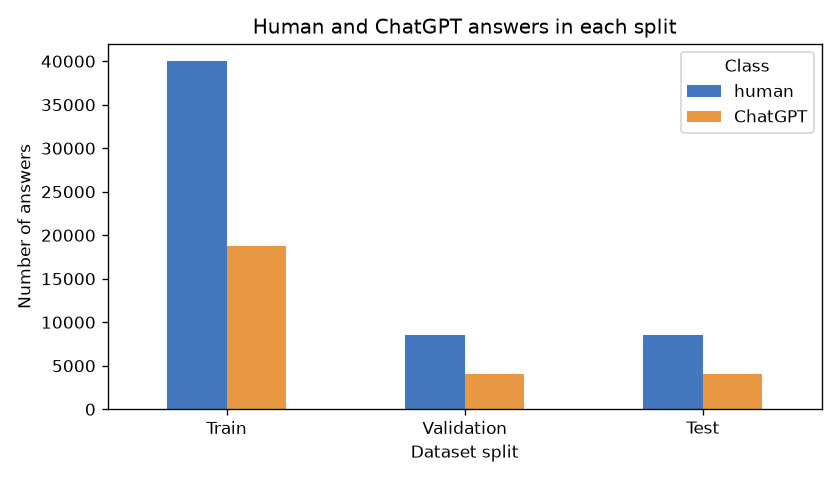

In [ ]:
class_counts = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_validation.value_counts(),
    "Test": y_test.value_counts(),
}).rename(index={0: "human", 1: "ChatGPT"})

class_counts.T.plot.bar(color=["#4378bf", "#e89842"], figsize=(7, 4))
plt.title("Human and ChatGPT answers in each split")
plt.xlabel("Dataset split")
plt.ylabel("Number of answers")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()


## 3. Select Regularization Strength (C) Using Validation Scores

In [4]:
C_VALUES = [0.1, 1.0, 4.0, 10.0, 20.0, 50.0, 100.0]
RANDOM_STATE = 42

validation_rows = []

for c_value in C_VALUES:
    candidate = LinearSVC(
        C=c_value,
        class_weight="balanced",
        dual="auto",
        max_iter=10000,
        random_state=RANDOM_STATE,
    )

    candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_validation)

    validation_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(
            y_validation,
            predictions,
        ),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
        ),
    })

validation_results = pd.DataFrame(validation_rows)

print(
    validation_results
    .round(4)
    .to_string(index=False)
)

best_c = float(
    validation_results
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    )
    .iloc[0]["C"]
)

print(
    f"Selected C={best_c:g} "
    "using validation macro-F1"
)

    C  accuracy  macro_f1
  0.1    0.9834    0.9809
  1.0    0.9890    0.9873
  4.0    0.9887    0.9870
 10.0    0.9886    0.9868
 20.0    0.9884    0.9867
 50.0    0.9884    0.9867
100.0    0.9880    0.9862
Selected C=1 using validation macro-F1


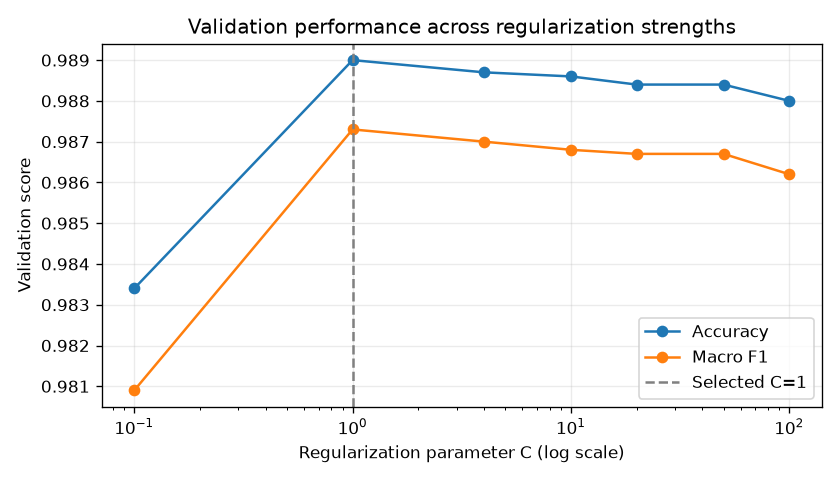

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(validation_results["C"], validation_results["accuracy"], marker="o", label="Accuracy")
ax.plot(validation_results["C"], validation_results["macro_f1"], marker="o", label="Macro F1")
ax.axvline(best_c, color="gray", linestyle="--", label=f"Selected C={best_c:g}")
ax.set_xscale("log")
ax.set_xlabel("Regularization parameter C (log scale)")
ax.set_ylabel("Validation score")
ax.set_title("Validation performance across regularization strengths")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 4. Train the Final SVM on Training and Validation Data

In [6]:
X_train_validation = vstack(
    [X_train, X_validation]
)

y_train_validation = pd.concat(
    [y_train, y_validation],
    ignore_index=True,
)

model = LinearSVC(
    C=best_c,
    class_weight="balanced",
    dual="auto",
    max_iter=10000,
    random_state=RANDOM_STATE,
)

model.fit(
    X_train_validation,
    y_train_validation,
)

test_predictions = model.predict(X_test)

## 5. Evaluate Test Performance and Classification Errors

Majority-class test accuracy: 0.6791
Accuracy:        0.9888
Macro precision: 0.9875
Macro recall:    0.9868
Macro F1:        0.9872

Per-class metrics:
              precision    recall  f1-score   support

       human       0.99      0.99      0.99      8579
     ChatGPT       0.98      0.98      0.98      4053

    accuracy                           0.99     12632
   macro avg       0.99      0.99      0.99     12632
weighted avg       0.99      0.99      0.99     12632



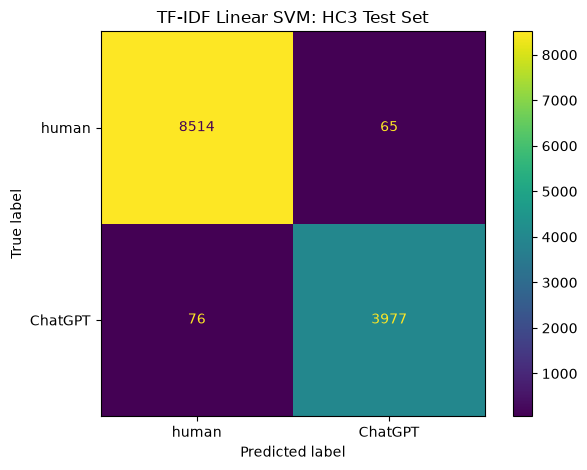

In [7]:
majority_prediction = int(
    y_train_validation.mode().iloc[0]
)

print(
    "Majority-class test accuracy:",
    f"{accuracy_score(y_test, np.full(len(y_test), majority_prediction)):.4f}",
)

print(
    f"Accuracy:        "
    f"{accuracy_score(y_test, test_predictions):.4f}"
)
print(
    f"Macro precision: "
    f"{precision_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)
print(
    f"Macro recall:    "
    f"{recall_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)
print(
    f"Macro F1:        "
    f"{f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)

print(
    "\nPer-class metrics:\n"
    + classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["human", "ChatGPT"],
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1],
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["human", "ChatGPT"],
).plot(values_format="d")

plt.title("TF-IDF Linear SVM: HC3 Test Set")
plt.tight_layout()
plt.show()

## 6. Save the Trained SVM Classifier

In [6]:
model_path = (
    TFIDF_MODEL_DIR
    / "linear_svm_model.joblib"
)

joblib.dump(
    {
        "classifier": model,
        "config": {
            "C": best_c,
            "class_weight": "balanced",
            "dual": "auto",
            "max_iter": 10000,
            "random_state": RANDOM_STATE,
            "vectorizer": "tfidf_vectorizer.joblib",
        },
    },
    model_path,
)

print(f"Saved Linear SVM model to {model_path}")

Saved Linear SVM model to ../../models/tfidf/linear_svm_model.joblib


## 7. Compare Class Weighting and Random Downsampling

In [9]:
comparison_c_values = [0.1, 1.0, 4.0, 10.0, 20.0, 50.0, 100.0]
comparison_seed = 42
minority_count = int(y_train.value_counts().min())
balanced_indices = train.groupby("target").sample(
    n=minority_count, random_state=comparison_seed
).index.to_numpy()

comparison_strategies = [
    ("Class weighting", X_train, y_train, "balanced"),
    ("Downsampling", X_train[balanced_indices], y_train.iloc[balanced_indices], None),
]

comparison_rows = []
for strategy, comparison_X, comparison_y, comparison_weight in comparison_strategies:
    for comparison_c in comparison_c_values:
        comparison_model = LinearSVC(
            C=comparison_c,
            class_weight=comparison_weight,
            dual="auto",
            max_iter=10000,
            random_state=comparison_seed,
        )
        comparison_model.fit(comparison_X, comparison_y)
        assert comparison_model.n_iter_ < 10000, "Model did not converge"
        comparison_predictions = comparison_model.predict(X_validation)
        comparison_recalls = recall_score(
            y_validation, comparison_predictions, labels=[0, 1],
            average=None, zero_division=0,
        )
        comparison_rows.append({
            "strategy": strategy,
            "C": comparison_c,
            "human_training_answers": int(comparison_y.eq(0).sum()),
            "ChatGPT_training_answers": int(comparison_y.eq(1).sum()),
            "accuracy": accuracy_score(y_validation, comparison_predictions),
            "macro_f1": f1_score(y_validation, comparison_predictions, average="macro"),
            "human_recall": comparison_recalls[0],
            "ChatGPT_recall": comparison_recalls[1],
        })
    print(f"Finished: {strategy}")

comparison_results = pd.DataFrame(comparison_rows)
comparison_best = comparison_results.sort_values(
    ["macro_f1", "accuracy", "C"], ascending=[False, False, True]
).drop_duplicates("strategy")
print(comparison_best.round(6).to_string(index=False))


Finished: Class weighting
Finished: Downsampling
       strategy   C  human_training_answers  ChatGPT_training_answers  accuracy  macro_f1  human_recall  ChatGPT_recall
Class weighting 1.0                   40024                     18799  0.988978  0.987296      0.994404        0.977436
   Downsampling 1.0                   18799                     18799  0.985647  0.983536      0.987759        0.981155


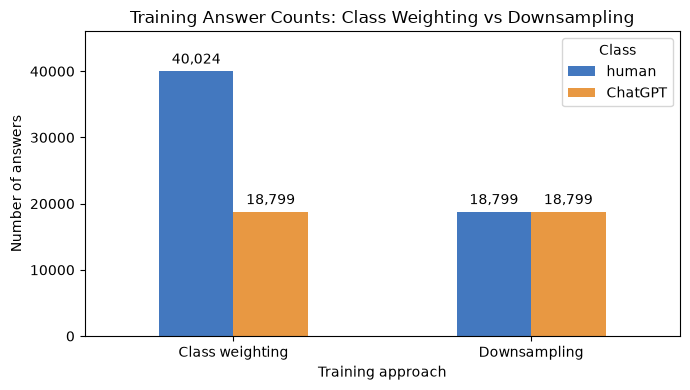

In [10]:
training_counts = comparison_best.set_index("strategy")[[
    "human_training_answers", "ChatGPT_training_answers"
]].reindex(["Class weighting", "Downsampling"]).rename(columns={
    "human_training_answers": "human",
    "ChatGPT_training_answers": "ChatGPT",
})

ax = training_counts.plot.bar(
    color=["#4378bf", "#e89842"], figsize=(7, 4), rot=0
)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set_title("Training Answer Counts: Class Weighting vs Downsampling")
ax.set_xlabel("Training approach")
ax.set_ylabel("Number of answers")
ax.set_ylim(0, training_counts.to_numpy().max() * 1.15)
ax.legend(title="Class")
plt.tight_layout()
plt.show()


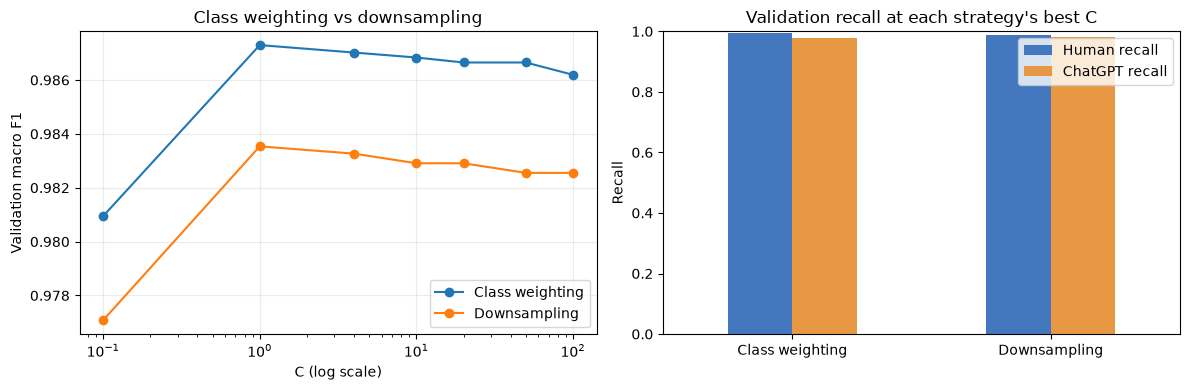

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for strategy, group in comparison_results.groupby("strategy", sort=False):
    axes[0].plot(group["C"], group["macro_f1"], marker="o", label=strategy)
axes[0].set_xscale("log")
axes[0].set_xlabel("C (log scale)")
axes[0].set_ylabel("Validation macro F1")
axes[0].set_title("Class weighting vs downsampling")
axes[0].legend()
axes[0].grid(alpha=0.25)

comparison_best.set_index("strategy")[["human_recall", "ChatGPT_recall"]].rename(
    columns={"human_recall": "Human recall", "ChatGPT_recall": "ChatGPT recall"}
).plot.bar(ax=axes[1], rot=0, color=["#4378bf", "#e89842"])
axes[1].set_title("Validation recall at each strategy's best C")
axes[1].set_xlabel("")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()
